# CT7 energy prediction: data pre-processing

Foundations of Data Engineering and Analytics, data analysis project · Lucas Alois Griesser, Luca Jenewein, Nikola Adžić · Winter Semester 2026/27

**Research question.** How accurately can the net battery energy of the CT7 over the next 5 seconds of driving be
predicted from the driver inputs and vehicle state of the preceding 5 seconds, and do standard machine-learning
models outperform a persistence baseline and a physics-based baseline on test days that were not used for training?

**Target.** The *net battery energy* of a 5-second window is E = Σ P · Δt over its 50 values (Δt = 0.1 s), in kJ,
where P is the power at the battery output reported by the ISA current and voltage sensor (it agrees closely with
U · I, see section 5). E > 0 means that the battery was discharged; E < 0 means that regenerative braking fed back more energy than the car used in that window.

**Input.** `data/ct7_can_extract.csv.gz` and `data/ct7_sessions.csv`, written by `00_extraction.ipynb` from the
raw CAN excerpt of the CT7 in `data/raw/` (run that notebook first). They are decoded and reduced, not raw. Everything
needed is part of the project package; this notebook does not need the original logs.

**Output.** `data/ct7_clean_10hz.csv.gz` (cleaned 10 Hz time series of all driving stints) and
`data/ct7_windows_5s.csv` (one row per pair of consecutive 5-second windows; the dataset for EDA and modelling).

| Section | Step |
|---|---|
| 1 | Data description and gathering |
| 2 | Timestamps, clock jumps and duplicates |
| 3 | Invalid values: fixed bounds, sentinels, frozen values |
| 4 | Time alignment on a 10 Hz grid |
| 5 | Consistency of power, voltage and current; sign convention |
| 6 | Missing values |
| 7 | Segmentation into driving stints |
| 8 | Feature windows and target |
| 9 | Bias and sampling |
| 10 | Output |

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("data")
GRID_S = 0.1      # 10 Hz grid
STALE_S = 1.0     # a value older than this is treated as missing
GAP_S = 2.0       # a longer gap starts a new recording block
MOVING_RPM = 300  # mean motor speed above which the car counts as moving
MAX_PAUSE_S = 20  # shorter stops do not end a stint
MIN_STINT_S = 10  # shorter stints are dropped
WINDOW = 50       # rows per window (5 s at 10 Hz)
WHEELS = ["rpm_fl", "rpm_fr", "rpm_rl", "rpm_rr"]

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e6e6e6",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE = "#2a78d6", "#eb6834"

## 1. Data description and gathering

The CT7 is the 2025 electric race car of the Formula Student team CTM. A Raspberry Pi in the car records all frames
of its four CAN buses (`can-main`, `can-inv`, `can-sense`, `can-ams`) with `candump` into one log file per power-up.
Between 24 April and 16 August 2025 this produced 528 log files (about 31 GiB; the files before 7 May are empty). CTM allowed the use of the logs for
this project and the submission of an excerpt of the raw frames together with the definitions of the selected
messages.

The logs were scanned once (`make_raw_excerpt.py`): files named 26 May 2025 or later, at most one frame per message
and 100 ms, and only periods in which a wheel motor turns faster than 100 1/min, plus 30 s before and after. The 130
earlier non-empty logs contain no driving with a battery power measurement: ISA frames appear in only 26 of them, and
in the four of these in which a wheel motor turns, a single motor exceeds 100 1/min for at most 4 s while the battery
current stays below 0.1 A. This check and the archive figures above come from the full logs, not from the package.
The included excerpt holds the raw frames of the selected periods. `00_extraction.ipynb` decodes them into 12 signals with the message
definitions from CTM's DBC file. Timestamps are seconds since the earliest thinned frame of each log file; a session
is one log file, and days are numbered D01, D02, ... in date order.

| Column | Meaning | Unit |
|---|---|---|
| `rpm_fl`, `rpm_fr`, `rpm_rl`, `rpm_rr` | speed of the four wheel hub motors (front/rear, left/right) | 1/min |
| `accel_pct`, `brake_pct`, `regen_pct` | accelerator pedal, brake pedal, regeneration request | % |
| `steer_deg` | steering angle | ° |
| `isa_current_a`, `isa_voltage_v`, `isa_power_w` | battery current, voltage and power (ISA sensor) | A, V, W |
| `cell_temp_max_c` | highest battery cell temperature (battery management system) | °C |

In [2]:
raw = pd.read_csv(DATA / "ct7_can_extract.csv.gz")
sessions = pd.read_csv(DATA / "ct7_sessions.csv")

print(f"{len(raw):,} rows, {raw.session_id.nunique()} sessions with data, "
      f"{sessions.day_id.nunique()} days with activity")
raw.groupby("signal").agg(rows=("value", "size"), sessions=("session_id", "nunique"))

7,041,760 rows, 120 sessions with data, 20 days with activity


,rows,sessions
signal,,
accel_pct,612661,117
brake_pct,612661,117
cell_temp_max_c,607579,109
isa_current_a,608069,109
isa_power_w,608007,109
isa_voltage_v,608061,109
regen_pct,612661,117
rpm_fl,593458,119
rpm_fr,599701,120


The session table from the extraction documents what was found in the log files of the sessions with data:

In [3]:
with_data = sessions[sessions.rows_written > 0].drop(columns=["session_id", "day_id"])
with_data.agg(["sum", "mean", "max"]).T.round(1)

,sum,mean,max
lines,462135827.0,3851131.9,27484939.0
malformed_lines,80.0,0.7,1.0
dlc_mismatch,1729093.0,14409.1,155052.0
frames_kept,16396452.0,136637.1,855238.0
rows_written,7041760.0,58681.3,443221.0
active_s,62397.6,520.0,3712.1
forward_gaps_over_60s,9.0,0.1,1.0
backward_steps_over_1s,217.0,1.8,108.0


- `malformed_lines`: lines that could not be parsed, mostly the last line of a file that was cut off when the
  logger was switched off.
- `dlc_mismatch`: frames of a selected message with a different length (counted in 100 ms intervals that do not yet
  have a valid frame of that message). Until 21 June 2025 the message with the
  steering angle had an older layout without that signal, so it could not be decoded.
- `forward_gaps_over_60s`, `backward_steps_over_1s`: clock effects, see section 2.

## 2. Timestamps, clock jumps and duplicates

Two clock effects were found by the scan of the full logs:

1. The Raspberry Pi has no battery-backed clock. After booting, it continues from an outdated time and jumps forward
   once it gets the correct time over the network. Values before and after such a jump must never end up in the same
   window.
2. Frames of different buses are not always written in time order (one bus is sometimes written later than the others; the scan
   counted 217 backward steps of more than 1 s in the sessions with data), so the file order is not the time order.

Checks: within one signal, the values must be in increasing time order in the file (otherwise the clock was set
back), and no value may appear twice.

In [4]:
back = raw.groupby(["session_id", "signal"]).t_s.diff() < 0  # rows are still in file order
print("time steps backwards within one signal (file order):", int(back.sum()))

raw = raw.sort_values(["session_id", "signal", "t_s"], kind="stable").reset_index(drop=True)
dupes = raw.duplicated(["session_id", "signal", "t_s"])
print("duplicate values (same session, signal and time):", int(dupes.sum()))
raw = raw[~dupes].reset_index(drop=True)

time steps backwards within one signal (file order): 0


duplicate values (same session, signal and time): 0


Sampling interval per signal (median time between two values of the same signal). The extraction kept at most
one value per message and 100 ms, so the typical interval is about 0.1 s.

In [5]:
step = raw.groupby(["session_id", "signal"]).t_s.diff()
step.groupby(raw.signal).median().round(3).to_frame("median interval [s]")

,median interval [s]
signal,
accel_pct,0.10
brake_pct,0.10
cell_temp_max_c,0.10
isa_current_a,0.10
isa_power_w,0.09
isa_voltage_v,0.10
regen_pct,0.10
rpm_fl,0.10
rpm_fr,0.10


**Recording blocks.** Inside a session, all values are sorted by time, and a new block starts after every gap
longer than 2 s. A gap separates either two active periods (the extraction removed the time in between) or the times
before and after a clock jump.

In [6]:
times = raw[["session_id", "t_s"]].drop_duplicates().sort_values(["session_id", "t_s"])
gap = times.groupby("session_id").t_s.diff()
times["block"] = (gap.isna() | (gap > GAP_S)).cumsum()
blocks = times.groupby("block").agg(session_id=("session_id", "first"),
                                    start=("t_s", "min"), end=("t_s", "max"))
print(len(blocks), "recording blocks in", blocks.session_id.nunique(), "sessions")

gaps = gap[gap > GAP_S]
print("gaps between blocks:", len(gaps))
labels = ["2-60 s", "1-60 min", "1-24 h", "> 1 day"]
sizes = pd.cut(gaps, [GAP_S, 60, 3600, 86400, np.inf], labels=labels)
print(sizes.value_counts().sort_index().to_string())
print("sessions with data and a forward clock jump over 60 s (scan):",
      int(((sessions.rows_written > 0) & (sessions.forward_gaps_over_60s > 0)).sum()))

409 recording blocks in 120 sessions
gaps between blocks: 289
t_s
2-60 s       93
1-60 min    196
1-24 h        0
> 1 day       0
sessions with data and a forward clock jump over 60 s (scan): 9


Forward clock jumps (found by the scan in 9 of the 120 sessions with data) cannot be told apart from ordinary gaps
in the extract. Either way, a new block starts at every gap over 2 s, and no value is carried across (section 4), so a
jump never ends up inside a window. Every value is now assigned to its block:

In [7]:
raw = raw.merge(times, on=["session_id", "t_s"], how="left")
assert raw.block.notna().all()

## 3. Invalid values: fixed bounds, sentinels, frozen values

Each signal has a range of physically possible values (fixed bounds). Values outside are set to missing, not
clipped, because a corrupted value says nothing about the true value.

In [8]:
BOUNDS = {  # signal: (lowest valid, highest valid, reason)
    "rpm": (-20000, 20000, "largest logged speed 19,935 1/min"),
    "accel_pct": (0, 100, "pedal position in percent"),
    "brake_pct": (0, 100, "pedal position in percent"),
    "regen_pct": (0, 100, "request in percent"),
    "steer_deg": (-150, 150, "-150.005 is the raw value -32768 (no valid angle)"),
    "isa_current_a": (-400, 400, "real values within +-185 A"),
    "isa_voltage_v": (300, 650, "battery voltage range"),
    "isa_power_w": (-150000, 150000, "real values within +-98 kW"),
    "cell_temp_max_c": (1, 80, "0.000 is sent when no temperature is available"),
}

rows = []
for signal, (low, high, reason) in BOUNDS.items():
    mask = raw.signal.str.startswith(signal) if signal == "rpm" else raw.signal == signal
    bad = mask & ~raw.value.between(low, high)
    rows.append([signal, low, high, int(mask.sum()), int(bad.sum()), reason])
    raw.loc[bad, "value"] = np.nan
pd.DataFrame(rows, columns=["signal", "low", "high", "values", "set missing", "reason"])

,signal,low,high,values,set missing,reason
0,rpm,-20000,20000,2357962,0,"largest logged speed 19,935 1/min"
1,accel_pct,0,100,612661,0,pedal position in percent
2,brake_pct,0,100,612661,0,pedal position in percent
3,regen_pct,0,100,612661,0,request in percent
4,steer_deg,-150,150,414099,646,-150.005 is the raw value -32768 (no valid angle)
5,isa_current_a,-400,400,608069,1,real values within +-185 A
6,isa_voltage_v,300,650,608061,0,battery voltage range
7,isa_power_w,-150000,150000,608007,4,real values within +-98 kW
8,cell_temp_max_c,1,80,607579,2808,0.000 is sent when no temperature is available


- **Battery power and current:** the largest real magnitudes are about 98 kW and 185 A. Four power values with magnitudes
  between 0.5 MW and 933 MW and one current of 5,589 A lie far outside this range; they are corrupted frames.
- **Cell temperature:** exactly 0.000 °C is sent while the battery management system has no measurement (a
  sentinel value). The lowest real value is 26.3 °C.
- **Steering angle:** −150.005° is the smallest 16-bit raw value (−32768) times the scale factor of the signal, a
  sentinel for "no valid angle". Values up to ±149.9° are real full-lock positions.
- **Motor speed and pedals:** no value outside the bounds. Small negative motor speeds (the car rolling backwards)
  are kept.

**Frozen values.** A motor speed that stays exactly the same (with a magnitude above 300 1/min) for at least 5 s cannot be real,
because the measured speed changes slightly every 100 ms. This happens when an inverter keeps sending its last value
after a fault; such values are set to missing as well.

In [9]:
same = ((raw.value == raw.value.shift()) & (raw.signal == raw.signal.shift())
        & (raw.session_id == raw.session_id.shift()))
run = (~same).cumsum()
duration = raw.groupby(run).t_s.transform("max") - raw.groupby(run).t_s.transform("min")
frozen = raw.signal.str.startswith("rpm_") & (raw.value.abs() > 300) & (duration >= 5)
print("frozen motor speed values:", int(frozen.sum()), "in", raw[frozen].signal.unique().tolist(),
      "over", round(duration[frozen].groupby(run[frozen]).first().sum()), "s")
raw.loc[frozen, "value"] = np.nan

frozen motor speed values: 1083 in ['rpm_fl'] over 108 s


## 4. Time alignment on a 10 Hz grid

The signals arrive at different times and rates. For each recording block a regular 10 Hz grid is built, and every
signal gets its most recent value that is at most 1 s old (`merge_asof`, backward). Older values count as missing,
so a signal that stops sending does not keep its last value, and nothing is carried from one block into another.
Values set to missing in section 3 are left out of the merge, so a row takes the last valid value if it is at most
1 s old.

In [10]:
grid = pd.concat(
    pd.DataFrame({"block": b, "session_id": r.session_id,
                  "t_s": np.round(np.arange(np.ceil(r.start * 10) / 10, r.end + 1e-9, GRID_S), 1)})
    for b, r in blocks.iterrows())
grid = grid.sort_values("t_s", kind="stable").reset_index(drop=True)

for signal, values in raw.dropna(subset=["value"]).groupby("signal"):
    values = (values[["block", "t_s", "value"]].sort_values("t_s", kind="stable")
              .rename(columns={"value": signal}))
    grid = pd.merge_asof(grid, values, on="t_s", by="block", direction="backward",
                         tolerance=STALE_S)

grid = grid.sort_values(["block", "t_s"]).reset_index(drop=True)
signals = sorted(raw.signal.unique())
print(f"{len(grid):,} grid rows in {grid.block.nunique()} blocks")
grid[signals].notna().mean().round(3).to_frame("share present")

615,004 grid rows in 409 blocks


,share present
accel_pct,0.996
brake_pct,0.996
cell_temp_max_c,0.984
isa_current_a,0.989
isa_power_w,0.989
isa_voltage_v,0.989
regen_pct,0.996
rpm_fl,0.964
rpm_fr,0.976
rpm_rl,0.943


## 5. Consistency of power, voltage and current; sign convention

The ISA sensor reports the power P in addition to the voltage U and the current I, so P should be close to U · I. The
three values come in separate CAN messages at different rates, so on the grid they can be up to 0.1 s apart. If the
remaining differences come from this timing and not from wrong values, they must be smallest when the series are
compared without a time shift, and they must average out over a window.

In [11]:
ui = grid.isa_voltage_v * grid.isa_current_a
both = grid.isa_power_w.notna() & ui.notna()
print("rows with P, U and I:", int(both.sum()))
print("correlation of P and U*I: %.4f" % np.corrcoef(grid.isa_power_w[both], ui[both])[0, 1])
for shift in [-1, 0, 1]:
    other = ui.groupby(grid.block).shift(shift)
    deviation = (grid.isa_power_w - other).abs()[both & other.notna()]
    print(f"shift {shift:+d} rows: median |P - U*I| = {deviation.median():5.0f} W, "
          f"99th percentile = {deviation.quantile(0.99):6.0f} W")
grid["ui_w"] = ui

rows with P, U and I: 607893
correlation of P and U*I: 0.9931
shift -1 rows: median |P - U*I| =     7 W, 99th percentile =  14491 W
shift +0 rows: median |P - U*I| =     6 W, 99th percentile =   3678 W
shift +1 rows: median |P - U*I| =     7 W, 99th percentile =  11476 W


The median deviation is a few watts, and the large single deviations are clearly smallest without a shift. They
come from the different sampling times during fast power changes, not from wrong values (the corrupted values were
already removed in section 3). No row is removed here; the check is repeated for whole 5-second windows in
section 8, where the target is defined.

**Sign convention.** The power should be positive while the driver accelerates and negative while the car
regenerates:

In [12]:
state = np.select([grid.accel_pct > 20, (grid.regen_pct > 20) | (grid.brake_pct > 20)],
                  ["accelerating (accel > 20 %)", "braking or regenerating (> 20 %)"], "other")
grid.groupby(state).isa_power_w.agg(["count", "median", "mean"]).round(0)

,count,median,mean
accelerating (accel > 20 %),121358,9419.0,12873.0
braking or regenerating (> 20 %),39577,-3.0,-4682.0
other,447061,-2.0,500.0


The median power is about 9 kW while accelerating and the mean is negative while braking, as expected. The median
of the braking rows is close to zero because the car does not always regenerate when the brake is pressed.

## 6. Missing values

The share of missing values (in %) is shown for the rows in which the car is moving, for the signals with more than
0.05 % missing on at least one day.
Missing values are not imputed: an invented power value would directly change the target, and the pedal positions
cannot be derived from other signals. Windows with missing required values are removed in section 8.

In [13]:
grid["rpm_mean"] = grid[WHEELS].mean(axis=1)
grid.loc[grid[WHEELS].notna().sum(axis=1) < 3, "rpm_mean"] = np.nan
grid = grid.merge(sessions[["session_id", "day_id"]], on="session_id", how="left")

moving = grid.rpm_mean > MOVING_RPM
missing = grid.loc[moving, signals].isna().groupby(grid.loc[moving, "day_id"]).mean() * 100
missing.loc[:, missing.max() > 0.05].round(1)

,rpm_fl,rpm_fr,rpm_rl,steer_deg
day_id,,,,
D03,3.8,0.0,1.4,100.0
D05,19.7,1.2,0.0,100.0
D06,0.0,0.0,0.0,100.0
D09,0.0,0.0,0.0,100.0
D10,4.3,0.1,0.1,100.0
D13,0.0,0.2,0.0,23.9
D14,0.0,0.0,0.0,0.0
D15,1.7,0.0,0.0,0.0
D16,0.0,0.0,0.0,0.0


- The steering angle is missing on all days before 21 June 2025 and in the first three sessions of that day
  (S135 to S137; older message layout, see section 1). It is kept
  as an optional feature and is not required for a window.
- Single motor speeds are missing for some periods (for example on D05). The mean motor speed is therefore taken over
  the available motors and set to missing if fewer than three report a value.
- On D01 only the two front motors were logged, so it contains no usable driving.
- All other signals are almost complete while the car is moving.

## 7. Segmentation into driving stints

A *stint* is a continuous drive inside one recording block: the mean motor speed (of at least three motors) is above
300 1/min, stops shorter than 20 s do not end it, and it lasts at least 10 s. Rows outside stints (standing, the margins
kept around activity) are dropped. In addition, a stint is only used if the battery delivered more
than 1 kW at least once; otherwise the wheels turned without drive power (probably because the car was pushed or rolled with the
high-voltage system switched off).

In [14]:
def stint_ids(block):
    """Number the stints of one block; rows outside a stint get NaN."""
    t, move = block.t_s.to_numpy(), (block.rpm_mean > MOVING_RPM).to_numpy()
    ids, n, start, end = np.full(len(block), np.nan), 0, None, None
    for i in np.flatnonzero(move):
        if end is not None and t[i] - t[end] > MAX_PAUSE_S:  # stop too long: close the stint
            if t[end] - t[start] >= MIN_STINT_S:
                ids[start:end + 1] = n
                n += 1
            start = None
        if start is None:
            start = i
        end = i
    if start is not None and t[end] - t[start] >= MIN_STINT_S:
        ids[start:end + 1] = n
    return pd.Series(ids, index=block.index)


grid["stint"] = grid.groupby("block", group_keys=False)[["t_s", "rpm_mean"]].apply(stint_ids)
stints = grid.dropna(subset=["stint"]).copy()
stints["stint_id"] = stints.groupby(["block", "stint"]).ngroup().map(lambda i: f"T{i + 1:03d}")
stints["t_in_stint_s"] = (stints.t_s - stints.groupby("stint_id").t_s.transform("min")).round(1)

peak = stints.groupby("stint_id").isa_power_w.max()
unpowered = peak[peak <= 1000]
print(stints.stint_id.nunique(), "stints found;", len(unpowered), "without drive power removed "
      f"(peak battery power <= 1 kW, median peak of these {unpowered.median():.0f} W)")
stints = stints[~stints.stint_id.isin(unpowered.index)].copy()

per_day = stints.groupby("day_id").agg(stints=("stint_id", "nunique"),
                                       minutes=("t_s", lambda s: len(s) / 600))
print(stints.stint_id.nunique(), "stints on", stints.day_id.nunique(), "days,",
      round(len(stints) / 36000, 2), "hours of driving")
per_day.round(1).T

345 stints found; 30 without drive power removed (peak battery power <= 1 kW, median peak of these 4 W)
315 stints on 11 days, 6.82 hours of driving


day_id,D03,D05,D10,D13,D14,D15,D16,D17,D18,D19,D20
stints,32.0,4.0,35.0,23.0,13.0,26.0,49.0,50.0,33.0,48.0,2.0
minutes,40.6,2.7,31.3,26.1,9.6,27.5,49.8,70.3,37.3,91.6,22.5


Example: the recording block with the most stints (shaded). The upper chart shows the mean motor speed, the
lower one the battery power from which the target is computed. Gaps in the lines are missing values.

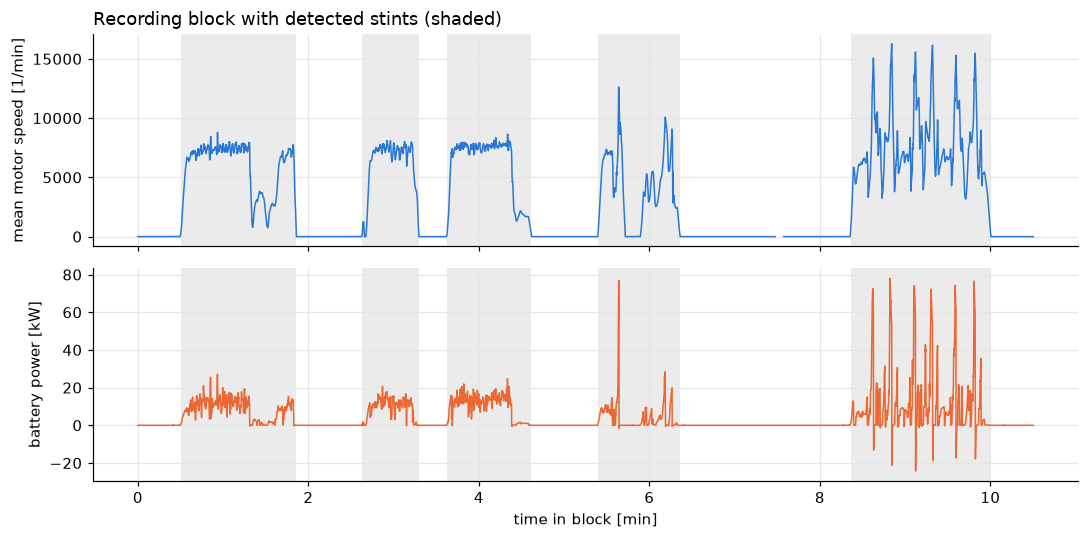

In [15]:
example = grid[grid.block == stints.groupby("block").stint_id.nunique().idxmax()]
used = example[example.index.isin(stints.index)]
x0 = example.t_s.min()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax1.plot((example.t_s - x0) / 60, example.rpm_mean, color=BLUE, lw=1)
ax1.set_ylabel("mean motor speed [1/min]")
ax2.plot((example.t_s - x0) / 60, example.isa_power_w / 1000, color=ORANGE, lw=1)
ax2.set_ylabel("battery power [kW]")
ax2.set_xlabel("time in block [min]")
for _, s in used.groupby("stint"):
    for ax in (ax1, ax2):
        ax.axvspan((s.t_s.min() - x0) / 60, (s.t_s.max() - x0) / 60,
                   color="#d9d9d9", alpha=0.5, lw=0)
ax1.set_title("Recording block with detected stints (shaded)", loc="left")
plt.tight_layout()
plt.show()

## 8. Feature windows and target

Each stint is cut into consecutive, non-overlapping windows of 5 s (50 grid rows) from its start; an incomplete last
window is dropped. Each row of the final dataset pairs a window w (features) with the following window w+1 of the
same stint (target). Features use only values of window w:

| Feature | Definition over window w |
|---|---|
| `rpm_mean` | mean of the mean motor speed |
| `rpm_delta` | mean motor speed at the end minus at the start of the window (acceleration proxy; missing if one of the two is missing) |
| `accel_mean`, `accel_max` | mean and maximum accelerator pedal position |
| `brake_mean`, `regen_mean` | mean brake pedal position and mean regeneration request |
| `steer_abs_mean` | mean absolute steering angle (missing until 21 June 2025) |
| `voltage_start` | battery voltage at the start of the window (state of charge proxy) |
| `cell_temp_max` | highest cell temperature in the window |
| `net_energy_kj` | net battery energy of window w |
| `t_in_stint_s` | time since the start of the stint |

Target: `net_energy_next_kj`, the net battery energy of window w+1 in kJ. Battery current, voltage and power of
window w+1 are not used as features, and motor torques or currents were not extracted at all, because they determine
the power almost directly. A window is used only if its power values are complete, so that its energy is not computed
over a gap.

In [16]:
stints["window"] = stints.groupby("stint_id").cumcount() // WINDOW
stints["steer_abs"] = stints.steer_deg.abs()
full = stints.groupby(["stint_id", "window"]).t_s.transform("size") == WINDOW
win = stints[full]

g = win.groupby(["stint_id", "window"])
windows = pd.DataFrame({
    "day_id": g.day_id.first(),
    "session_id": g.session_id.first(),
    "t_in_stint_s": g.t_in_stint_s.first(),
    "rpm_mean": g.rpm_mean.mean(),
    "rpm_delta": g.rpm_mean.agg(lambda s: s.iloc[-1] - s.iloc[0]),
    "accel_mean": g.accel_pct.mean(),
    "accel_max": g.accel_pct.max(),
    "brake_mean": g.brake_pct.mean(),
    "regen_mean": g.regen_pct.mean(),
    "steer_abs_mean": g.steer_abs.mean(),
    "voltage_start": g.isa_voltage_v.first(),
    "cell_temp_max": g.cell_temp_max_c.max(),
    "net_energy_kj": g.isa_power_w.sum() * GRID_S / 1000,
    "ui_energy_kj": g.ui_w.sum() * GRID_S / 1000,
    "power_complete": g.isa_power_w.count() == WINDOW,
}).reset_index()

nxt = windows[["stint_id", "window", "net_energy_kj", "ui_energy_kj", "power_complete"]].copy()
nxt["window"] -= 1
data = windows.merge(nxt, on=["stint_id", "window"], suffixes=("", "_next"))
data = data.rename(columns={"net_energy_kj_next": "net_energy_next_kj",
                            "ui_energy_kj_next": "ui_energy_next_kj"})
print(len(windows), "complete windows,", len(data), "pairs of consecutive windows")

4757 complete windows, 4442 pairs of consecutive windows


Pairs with incomplete power (in either window) or missing required features are removed. Then the consistency
check from section 5 is repeated for whole windows: the energy from P must agree with the energy from U · I. Pairs in
which a window differs by more than 2 kJ and 20 % are removed, because one of the values is not reliable there.
Because these conditions also concern window w+1, the dataset only contains pairs in which the car still drives with
complete and consistent power data in the next window.

In [17]:
required = ["rpm_mean", "rpm_delta", "accel_mean", "accel_max", "brake_mean", "regen_mean",
            "voltage_start", "cell_temp_max", "net_energy_kj", "net_energy_next_kj"]
ok_power = data.power_complete & data.power_complete_next
ok_features = data[required].notna().all(axis=1)
print("pairs with incomplete power:", int((~ok_power).sum()))
print("pairs with other missing required values:", int((ok_power & ~ok_features).sum()))
data = data[ok_power & ok_features].reset_index(drop=True)


def inconsistent(energy, energy_ui):
    """Energy from P differs from the energy from U*I by more than 2 kJ and 20 %."""
    diff = (energy - energy_ui).abs()
    return (diff > 2) & (diff / energy_ui.abs().clip(lower=1) > 0.2)


relative = ((data.net_energy_next_kj - data.ui_energy_next_kj).abs()
            / data.ui_energy_next_kj.abs().clip(lower=1))
print("target windows: median relative difference between the two energies %.1f %%"
      % (100 * relative.median()))
bad = (inconsistent(data.net_energy_kj, data.ui_energy_kj)
       | inconsistent(data.net_energy_next_kj, data.ui_energy_next_kj))
print("pairs with an inconsistent window:", int(bad.sum()))
data = data[~bad].drop(columns=["power_complete", "power_complete_next", "ui_energy_kj",
                                "ui_energy_next_kj"]).reset_index(drop=True)
print(len(data), "pairs remain")

pairs with incomplete power: 1
pairs with other missing required values: 12
target windows: median relative difference between the two energies 0.7 %
pairs with an inconsistent window: 28
4401 pairs remain


**Leakage checks.** The target must come from the window directly after the feature window in the same stint, and
it must equal the energy recomputed from the cleaned 10 Hz data. A feature computed from window w+1 would make the
prediction trivial, so three features of window w (`net_energy_kj`, `accel_mean`, `rpm_delta`) are recomputed as well, for 20 random
rows.

In [18]:
for _, r in data.sample(20, random_state=0).iterrows():
    this = win[(win.stint_id == r.stint_id) & (win.window == r.window)]
    following = win[(win.stint_id == r.stint_id) & (win.window == r.window + 1)]
    assert len(this) == WINDOW and len(following) == WINDOW
    assert np.isclose(following.t_s.min() - this.t_s.max(), GRID_S)  # directly after, same block
    assert np.isclose(following.isa_power_w.sum() * GRID_S / 1000, r.net_energy_next_kj)
    assert np.isclose(this.isa_power_w.sum() * GRID_S / 1000, r.net_energy_kj)
    assert np.isclose(this.accel_pct.mean(), r.accel_mean)
    assert np.isclose(this.rpm_mean.iloc[-1] - this.rpm_mean.iloc[0], r.rpm_delta)
print("target and features recomputed for 20 random rows: ok")

target and features recomputed for 20 random rows: ok


## 9. Bias and sampling

The dataset is not a random sample of how the car is driven:

- **Unequal days.** The number of windows differs strongly between days (table below), and neighbouring windows of
  the same stint are not independent (speed, battery voltage and temperature change little from one window to the
  next). A model evaluated on randomly mixed windows would mainly learn the large
  days and look better than it is (random cross-validation underestimates the error for dependent data, Roberts
  et al. 2017). Evaluation will therefore always hold out whole days (leave-one-day-out), and
  results will also be reported per day.
- **Test drives only.** All data come from test drives, not from competition events; how much of the driving is
  endurance-like is unknown.
- **Selection by the activity filter.** The extraction kept only periods in which a wheel motor turned faster than
  100 1/min, plus 30 s before and after. Every stint row lies within 21 s of such a motor speed (moving rows within
  1 s, stops shorter than 20 s), so the filter removes no driving, only standing and very slow rolling. While the car
  stands within the kept periods (8.5 h), the battery power is close to zero (second table below), so the standing time
  that was not extracted very likely holds little energy as well; this cannot be measured from the extract.
- **Selection by the stint rules.** Slow manoeuvring below 300 1/min, stops longer than 20 s and rolling without
  drive power are excluded, so the dataset describes powered driving only. 98.5 % of the net battery energy in the
  kept periods lies in stints; most of the rest (2.0 MJ) falls in rows with fewer than three motor speeds. A wheel motor
  turned on 20 days, but only 11 of them contain usable powered driving (first table below): on D01 only the front motors
  were logged, and on the other eight days the car drove above 300 1/min for less than a minute or without drive
  power.
- **Sampling.** Windows do not overlap, so each value of the 10 Hz series is used in at most one feature window and
  one target window. No further subsampling is applied.

In [19]:
summary = grid.groupby("day_id").agg(moving_min=("rpm_mean", lambda s: (s > MOVING_RPM).sum() / 600),
                                     peak_power_kw=("isa_power_w", lambda p: p.max() / 1000))
summary = summary.join(data.groupby("day_id").agg(stints=("stint_id", "nunique"), windows=("window", "size"),
                                                  mean_target_kj=("net_energy_next_kj", "mean")))
summary[["stints", "windows"]] = summary[["stints", "windows"]].fillna(0).astype(int)
summary["share_pct"] = summary.windows / summary.windows.sum() * 100
summary.round(1)

,moving_min,peak_power_kw,stints,windows,mean_target_kj,share_pct
day_id,,,,,,
D01,0.0,9.8,0,0,NaN,0.0
D02,0.0,NaN,0,0,NaN,0.0
D03,38.8,68.9,32,436,20.6,9.9
D04,0.0,0.0,0,0,NaN,0.0
D05,3.2,52.4,4,27,13.1,0.6
D06,2.0,0.0,0,0,NaN,0.0
D07,0.0,0.0,0,0,NaN,0.0
D08,0.0,NaN,0,0,NaN,0.0
D09,0.0,0.4,0,0,NaN,0.0


In [20]:
speed = np.select([grid.rpm_mean.isna(), grid.rpm_mean.abs() < 100, grid.rpm_mean > MOVING_RPM],
                  ["fewer than 3 motors", "below 100 1/min", "above 300 1/min"], "100-300 1/min or backwards")
in_stint = np.where(grid.index.isin(stints.index), "in a stint", "not in a stint")
print("net battery energy in stints: %.1f %% of the kept periods"
      % (100 * grid.isa_power_w[in_stint == "in a stint"].sum() / grid.isa_power_w.sum()))
power = grid.isa_power_w.groupby([speed, in_stint])
pd.DataFrame({"hours": power.size() / 36000, "mean power [kW]": power.mean() / 1000,
              "energy [MJ]": power.sum() * GRID_S / 1e6}).reindex(
    ["below 100 1/min", "100-300 1/min or backwards", "above 300 1/min", "fewer than 3 motors"], level=0).round(2)

net battery energy in stints: 98.5 % of the kept periods


hours  mean power [kW]  energy [MJ]
below 100 1/min            in a stint       0.26             0.04         0.04
                           not in a stint   8.45             0.00         0.00
100-300 1/min or backwards in a stint       0.06             0.15         0.04
                           not in a stint   0.50             0.03         0.06
above 300 1/min            in a stint       6.49             6.75       157.62
                           not in a stint   0.29             0.29         0.31
fewer than 3 motors        in a stint       0.01             0.00         0.00
                           not in a stint   1.02             0.57         1.99

## 10. Output

The cleaned 10 Hz stint data are kept for later plots of whole drives; the window dataset is the input for EDA and
modelling. Both are written in a fixed row order, so every run produces identical files (compare the printed hashes).

In [21]:
clean_cols = ["day_id", "session_id", "stint_id", "t_in_stint_s", "rpm_mean"] + signals
clean = stints[clean_cols].sort_values(["stint_id", "t_in_stint_s"])
clean.to_csv(DATA / "ct7_clean_10hz.csv.gz", index=False, float_format="%.6g",
             compression={"method": "gzip", "mtime": 0})

out_cols = ["day_id", "session_id", "stint_id", "window", "t_in_stint_s", "rpm_mean",
            "rpm_delta", "accel_mean", "accel_max", "brake_mean", "regen_mean", "steer_abs_mean",
            "voltage_start", "cell_temp_max", "net_energy_kj", "net_energy_next_kj"]
data = data[out_cols].sort_values(["stint_id", "window"]).reset_index(drop=True)
data.to_csv(DATA / "ct7_windows_5s.csv", index=False, float_format="%.6g")

for name in ["ct7_clean_10hz.csv.gz", "ct7_windows_5s.csv"]:
    path = DATA / name
    digest = hashlib.sha256(path.read_bytes()).hexdigest()[:16]
    print(f"{name}: {path.stat().st_size / 2**20:.2f} MiB, sha256 {digest}")
print(data.shape)
data.head().T

ct7_clean_10hz.csv.gz: 6.75 MiB, sha256 df394d208c7753ad
ct7_windows_5s.csv: 0.36 MiB, sha256 c9b7fbd83d3f6d84
(4401, 16)


,0,1,2,3,4
day_id,D03,D03,D03,D03,D03
session_id,S020,S020,S020,S020,S020
stint_id,T001,T001,T001,T001,T001
window,0,1,2,3,4
t_in_stint_s,0.0,5.0,10.0,15.0,20.0
rpm_mean,710.68,787.88,1035.14,887.135,1766.93
rpm_delta,-286.5,-989.5,1874.0,1635.0,-1509.25
accel_mean,5.68,5.84,3.58,4.02,6.48
accel_max,19.0,21.0,26.0,20.0,13.0
brake_mean,0.0,0.0,0.0,0.0,0.0


Sanity check of the final dataset (the exploratory analysis follows in the EDA milestone):

In [22]:
print("days:", data.day_id.nunique(), " stints:", data.stint_id.nunique())
print("missing values:", data.isna().sum()[data.isna().sum() > 0].to_dict())
print("windows with negative target (net regeneration): %.1f %%"
      % (100 * (data.net_energy_next_kj < 0).mean()))
data[["net_energy_next_kj", "net_energy_kj", "rpm_mean", "accel_mean"]].describe().round(2)

days: 11  stints: 315
missing values: {'steer_abs_mean': 847}
windows with negative target (net regeneration): 4.3 %


,net_energy_next_kj,net_energy_kj,rpm_mean,accel_mean
count,4401.00,4401.00,4401.00,4401.00
mean,33.96,34.44,6121.36,22.30
std,31.91,31.63,3091.48,13.44
min,-52.91,-52.91,-70.65,0.00
25%,7.02,8.85,3964.56,14.14
50%,27.50,27.67,6510.56,20.90
75%,50.47,50.47,7889.48,28.94
max,226.42,226.42,15823.08,100.00


## References

- D. R. Roberts et al. Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic
  structure. *Ecography* 40:913–929, 2017. https://doi.org/10.1111/ecog.02881 (section 9: why whole days are held out)
- T. Gebru et al. Datasheets for datasets. arXiv:1803.09010v8, 2021 (structure of `datasheet.pdf`)
- Related work on the energy prediction of electric vehicles (De Cauwer et al. 2015; Huang et al. 2024) is discussed in
  `concept.pdf`.